# H4 · How did Thiel's named companies do after the book? (ch. 3, 5, 6, 12, 13)

*Zero to One* was published in the US on **16 September 2014**. The book uses public companies as examples, some as models and some as warnings. This notebook asks a simple question: what would a reader who bought those stocks on publication day have earned to today, against the S&P 500?

| Group | Companies | Thiel's point |
|---|---|---|
| **Monopolies and definite planners** | Alphabet (Google), Meta (Facebook), Apple, Amazon, Microsoft, Tesla, eBay together with PayPal | Monopoly profits (ch. 3), starting small and scaling (ch. 5), definite plans (ch. 6), and the one cleantech firm that answered all seven questions (ch. 13) |
| **Valued on distant cash flows** | LinkedIn, Twitter | Most of their value lay a decade or more ahead (ch. 5) |
| **Fast growth, doubtful durability** | Groupon, Zynga | Rapid growth without a defensible position (ch. 5) |
| **Foils** | US airlines (Delta, United, American, Southwest, Alaska, JetBlue), the New York Times | Competition destroys profits (ch. 3); the Times was worth less than loss-making Twitter (ch. 5) |
| **Later addition** | Palantir, from its 2020 listing | Computers complementing humans (ch. 12); Thiel co-founded it |

**How returns are measured**
* **Total return:** dividends are reinvested. Yahoo's adjusted close provides this.
* **Acquired firms** are valued at the deal price on the closing date. LinkedIn was bought by Microsoft for $196 cash (8 Dec 2016). Twitter went private at $54.20 cash (27 Oct 2022). Zynga was bought by Take-Two for $3.50 cash plus 0.0406 Take-Two shares (23 May 2022). After the deal, the proceeds are either reinvested in the S&P 500 (the main figure) or held as cash (shown for comparison).
* **eBay and PayPal:** a 2014 eBay holder received one PayPal share per eBay share when PayPal was spun off in July 2015. They are treated as one position, using split-adjusted prices without dividends (eBay's dividend began only in 2019 and is small).
* **Benchmark:** SPY (S&P 500, total return), plus QQQ (Nasdaq-100) for reference.

**Interpretation caveat.** This is a scorecard, not a test of cause. A handful of named stocks over one decade cannot prove a theory, and the book's examples were chosen with hindsight to fit its argument. Sections H1–H3 test the general claims.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sys; from pathlib import Path  # thiel_common.py lives in the repo root
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "thiel_common.py").exists())))
import thiel_common as tc
tc.style()
START = pd.Timestamp("2014-09-16")
print("synthetic mode" if tc.SYNTHETIC else "live data")

live data


## Settings

Yahoo no longer carries the delisted tickers LinkedIn (LNKD), Twitter (TWTR) and Zynga (ZNGA). Their daily closes up to each deal come from `reference/delisted_prices.csv`, built from public copies of Yahoo's history; each row records its source. `MANUAL_START` is a last resort that gives the end value but no daily path.

In [2]:
GROUPS = {
    "Monopolies and definite planners": ["GOOGL", "META", "AAPL", "AMZN", "MSFT", "TSLA", "EBAY+PYPL"],
    "Valued on distant cash flows":     ["LNKD", "TWTR"],
    "Fast growth, doubtful durability": ["GRPN", "ZNGA"],
    "Foils: airlines and the NYT":      ["AIRLINES", "NYT"],
}
LATER = {"PLTR": pd.Timestamp("2020-09-30")}
AIRLINES = ["DAL", "UAL", "AAL", "LUV", "ALK", "JBLU"]
NAMES = {"GOOGL": "Alphabet", "META": "Meta", "AAPL": "Apple", "AMZN": "Amazon", "MSFT": "Microsoft", "TSLA": "Tesla",
         "EBAY+PYPL": "eBay + PayPal", "LNKD": "LinkedIn", "TWTR": "Twitter", "GRPN": "Groupon", "ZNGA": "Zynga",
         "AIRLINES": "US airlines (6, equal weight)", "NYT": "New York Times", "PLTR": "Palantir", "SPY": "S&P 500 (SPY)",
         "QQQ": "Nasdaq-100 (QQQ)"}
DEALS = {  # ticker: (closing date, cash per share, (acquirer ticker, shares per share) or None)
    "LNKD": (pd.Timestamp("2016-12-08"), 196.00, None),
    "TWTR": (pd.Timestamp("2022-10-27"), 54.20, None),
    "ZNGA": (pd.Timestamp("2022-05-23"), 3.50, ("TTWO", 0.0406)),
}
# Daily closes for the delisted tickers, from public copies of Yahoo's history (sources in the file's 'source' column):
# LinkedIn to 7 Dec 2016, Twitter to 27 Oct 2022, Zynga to 23 May 2022. Their 16 Sep 2014 closes ($212.38, $50.83,
# $3.02) match several other independent copies.
REF = pd.read_csv(tc.ROOT / "reference" / "delisted_prices.csv", parse_dates=["date"])
# Last resort if a ticker has no daily history anywhere: its 16 Sep 2014 close (gives the end value but no path)
MANUAL_START = {"LNKD": 212.38, "TWTR": 50.83, "ZNGA": 3.02}

spy = tc.yahoo_close("SPY")
END = spy.index.max()
cal = spy.loc[START:END].index                      # trading calendar
print(f"Window: {START:%d %b %Y} to {END:%d %b %Y} ({(END - START).days / 365.25:.1f} years)")

Window: 16 Sep 2014 to 06 Nov 2026 (12.1 years)


## Build a wealth path for each company: $1 invested at the start

In [3]:
def path_from(px, start=START):
    px = px.reindex(cal.union(px.index)).ffill().reindex(cal).loc[start:]
    return px / px.iloc[0]

def price_any(t, adjusted=True, until=None):
    s = tc.yahoo_close(t, adjusted=adjusted)
    # a delisted ticker can be reused by a new security: reject series that run well past the deal date
    if until is not None and len(s) and s.index.max() > until + pd.Timedelta(days=30):
        print(f"{t}: Yahoo series runs to {s.index.max():%Y-%m-%d}, after the {until:%Y-%m-%d} deal; ignored as a different security")
        s = pd.Series(dtype=float)
    if len(s.loc[:START + pd.Timedelta(days=5)]) == 0 or len(s) < 50:
        if t in REF.ticker.values:                     # bundled daily history for delisted tickers
            s = REF[REF.ticker == t].set_index("date").close.rename(t)
        else:
            alt = tc.stooq_close(t.lower() + ".us")
            if len(alt) > len(s): s = alt
    return s

W, notes, missing = {}, {}, []
spy_tr = path_from(spy)

for t in ["GOOGL", "META", "AAPL", "AMZN", "MSFT", "TSLA", "GRPN", "NYT", "QQQ"]:
    s = price_any(t)
    if len(s.loc[:START]) == 0: missing.append(t); continue
    W[t] = path_from(s)

# eBay + PayPal: one eBay share, plus one PayPal share from the 20 Jul 2015 spin-off (price only)
ebay, pypl = price_any("EBAY", adjusted=False), price_any("PYPL", adjusted=False)
if len(ebay.loc[:START]):
    e = ebay.reindex(cal).ffill(); p = pypl.reindex(cal).ffill().fillna(0)
    W["EBAY+PYPL"] = (e + p) / e.loc[START]
    notes["EBAY+PYPL"] = "price only (no dividends); PayPal added at the July 2015 spin-off"

# Airlines: equal-weight buy and hold of six carriers
air = [path_from(price_any(t)) for t in AIRLINES if len(price_any(t).loc[:START])]
if air: W["AIRLINES"] = pd.concat(air, axis=1).mean(axis=1); notes["AIRLINES"] = f"{len(air)} carriers, equal weight"

# Acquired firms: price to the deal date, deal value at closing, then proceeds in SPY (main) or cash (alt)
W_cash = {}
for t, (dd, cash, stock) in DEALS.items():
    s = price_any(t, adjusted=False, until=dd)
    if len(s) and s.index.max() > dd + pd.Timedelta(days=30): s = pd.Series(dtype=float)
    p0 = s.loc[:START].iloc[-1] if len(s.loc[:START]) else MANUAL_START.get(t)
    if p0 is None: missing.append(t); continue
    # with only a manual start price there is no daily path before the deal: anchor $1 on the start date
    pre = (s.reindex(cal).ffill().loc[START:dd] / p0) if len(s.loc[:START]) else pd.Series([1.0], index=[cal[0]])
    stock_val = 0.0
    if stock:
        a = price_any(stock[0], adjusted=False)
        stock_val = stock[1] * a.loc[:dd].iloc[-1]
    v_deal = (cash + stock_val) / p0
    post_idx = cal[cal > dd]
    if stock:
        a_tr = path_from(price_any(stock[0]), start=dd)            # acquirer total return from closing
        stock_part = stock_val / p0 * a_tr.reindex(post_idx)
        cash_spy = cash / p0 * (spy_tr.reindex(post_idx) / spy_tr.loc[:dd].iloc[-1])
        W[t] = pd.concat([pre, pd.Series(v_deal, index=[dd]), stock_part + cash_spy])
        W_cash[t] = pd.concat([pre, pd.Series(v_deal, index=[dd]), stock_part + cash / p0])
    else:
        W[t] = pd.concat([pre, pd.Series(v_deal, index=[dd]), v_deal * spy_tr.reindex(post_idx) / spy_tr.loc[:dd].iloc[-1]])
        W_cash[t] = pd.concat([pre, pd.Series(v_deal, index=[dd]), pd.Series(v_deal, index=post_idx)])
    W[t] = W[t][~W[t].index.duplicated(keep="last")]; W_cash[t] = W_cash[t][~W_cash[t].index.duplicated(keep="last")]
    notes[t] = f"acquired {dd:%d %b %Y}: ${cash:.2f} cash" + (f" + {stock[1]} {stock[0]}" if stock else "") + \
               ("" if len(s.loc[:START]) else "; start price entered manually, no path before the deal")

for t, d0 in LATER.items():
    s = price_any(t)
    if len(s): W[t] = path_from(s, start=max(d0, s.index.min()))

W["SPY"] = spy_tr
print("Built:", ", ".join(NAMES.get(k, k) for k in W))
if missing: print("\nMISSING (fill MANUAL_START or check the ticker):", missing)

Built: Alphabet, Meta, Apple, Amazon, Microsoft, Tesla, Groupon, New York Times, Nasdaq-100 (QQQ), eBay + PayPal, US airlines (6, equal weight), LinkedIn, Twitter, Zynga, Palantir, S&P 500 (SPY)


## Scorecard

* **Multiple:** what $1 became by the end date. **CAGR:** the annualised return.
* **vs S&P 500:** the company's multiple divided by SPY's multiple over the same window. Above 1 means it beat the index.
* **Max drawdown:** the largest fall from a previous high along the way.

In [4]:
def stats(w, label):
    w = w.dropna()
    if w.empty: return None
    s0, s1 = w.index[0], w.index[-1]
    yrs = (s1 - s0).days / 365.25
    bench = spy_tr.loc[s1] / spy_tr.loc[:s0].iloc[-1]
    dd = (w / w.cummax() - 1).min()
    return {"name": NAMES.get(label, label), "ticker": label, "start": s0.date(), "end": s1.date(),
            "multiple": w.iloc[-1] / w.iloc[0], "cagr_pct": 100 * ((w.iloc[-1] / w.iloc[0]) ** (1 / yrs) - 1),
            "spy_multiple": bench, "vs_spy": (w.iloc[-1] / w.iloc[0]) / bench, "max_drawdown_pct": 100 * dd,
            "note": notes.get(label, "")}

rows = []
for g, members in GROUPS.items():
    for t in members:
        if t in W:
            r = stats(W[t], t); r["group"] = g; rows.append(r)
for t in LATER:
    if t in W: r = stats(W[t], t); r["group"] = "Later addition (from listing)"; rows.append(r)
for t in ["SPY", "QQQ"]:
    if t in W: r = stats(W[t], t); r["group"] = "Benchmarks"; rows.append(r)
score = pd.DataFrame(rows)
tc.save_table(score, "h4_scorecard", index=False)

alt = pd.DataFrame([{**stats(W_cash[t], t), "group": "proceeds held as cash"} for t in W_cash])
tc.save_table(alt, "h4_deals_cash_alternative", index=False)

grp = {}
for g, members in GROUPS.items():
    ws = [W[t].reindex(cal).ffill() for t in members if t in W]
    if ws: grp[g] = pd.concat(ws, axis=1).mean(axis=1)
gs = pd.DataFrame([{**stats(w, g), "group": g, "n": sum(t in W for t in GROUPS[g])} for g, w in grp.items()])
tc.save_table(gs, "h4_group_portfolios", index=False)
print("Equal-weight group portfolios bought on publication day:")
print(gs[["name", "n", "multiple", "cagr_pct", "vs_spy", "max_drawdown_pct"]].round(2).to_string(index=False))
score[["group", "name", "start", "end", "multiple", "cagr_pct", "vs_spy", "max_drawdown_pct", "note"]].round(2)

Equal-weight group portfolios bought on publication day:
                            name  n  multiple  cagr_pct  vs_spy  max_drawdown_pct
Monopolies and definite planners  7     13.08     23.59    2.91            -55.55
    Valued on distant cash flows  2      2.85      9.01    0.63            -66.59
Fast growth, doubtful durability  2      2.64      8.33    0.59            -56.03
     Foils: airlines and the NYT  2      3.89     11.83    0.86            -48.30


,group,name,start,end,multiple,cagr_pct,vs_spy,max_drawdown_pct,note
0,Monopolies and definite planners,Alphabet,2014-09-16,2026-11-06,9.77,20.65,2.17,-44.32,
1,Monopolies and definite planners,Meta,2014-09-16,2026-11-06,8.10,18.80,1.80,-76.74,
2,Monopolies and definite planners,Apple,2014-09-16,2026-11-06,15.42,25.28,3.43,-38.52,
3,Monopolies and definite planners,Amazon,2014-09-16,2026-11-06,15.82,25.54,3.52,-56.15,
4,Monopolies and definite planners,Microsoft,2014-09-16,2026-11-06,13.48,23.90,3.00,-37.15,
5,Monopolies and definite planners,Tesla,2014-09-16,2026-11-06,20.61,28.30,4.58,-73.63,
6,Monopolies and definite planners,eBay + PayPal,2014-09-16,2026-11-06,8.34,19.09,1.86,-76.87,price only (no dividends); PayPal added at the...
7,Valued on distant cash flows,LinkedIn,2014-09-16,2026-11-06,3.53,10.95,0.78,-62.70,acquired 08 Dec 2016: $196.00 cash
8,Valued on distant cash flows,Twitter,2014-09-16,2026-11-06,2.17,6.60,0.48,-74.72,acquired 27 Oct 2022: $54.20 cash
9,"Fast growth, doubtful durability",Groupon,2014-09-16,2026-11-06,0.11,-16.54,0.02,-98.21,


### Figure H4-1 · $1 invested on publication day, by group (equal weight, log scale)

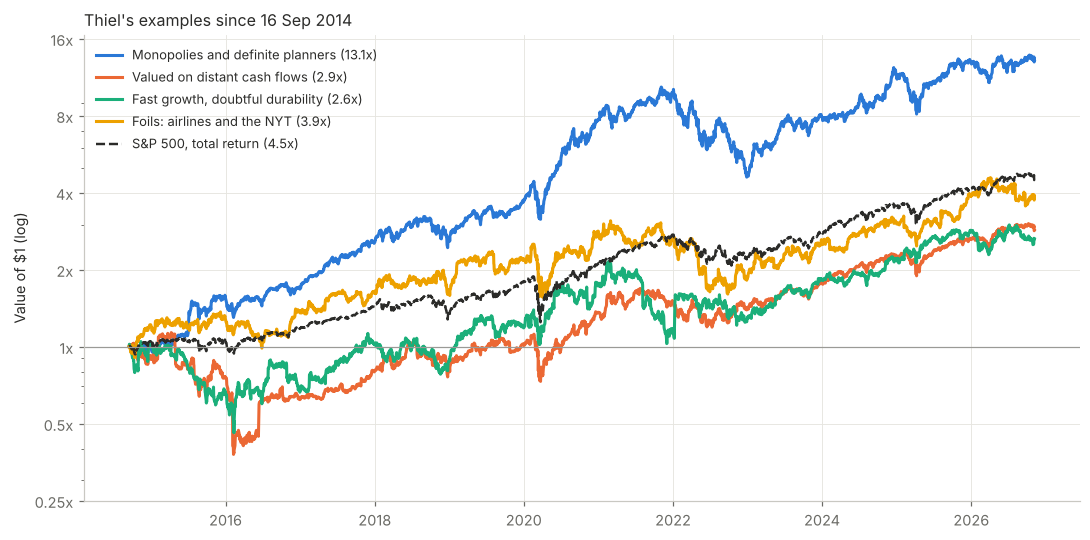

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
for i, (g, w) in enumerate(grp.items()):
    ax.plot(w.index, w.values, color=tc.C[i], lw=2, label=f"{g} ({w.iloc[-1]:.1f}x)")
ax.plot(spy_tr.index, spy_tr.values, color=tc.INK, lw=1.6, ls="--", label=f"S&P 500, total return ({spy_tr.iloc[-1]:.1f}x)")
ax.set_yscale("log"); ax.axhline(1, color=tc.GREY, lw=0.8)
ticks = [0.25, 0.5, 1, 2, 4, 8, 16]
ax.set_yticks(ticks); ax.set_yticklabels([f"{v:g}x" for v in ticks])
ax.set_ylabel("Value of $1 (log)"); ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("Thiel's examples since 16 Sep 2014", loc="left")
fig.tight_layout(); tc.save_fig(fig, "h4_fig1_groups")

### Figure H4-2 · Each company's multiple against the S&P 500 over the same window

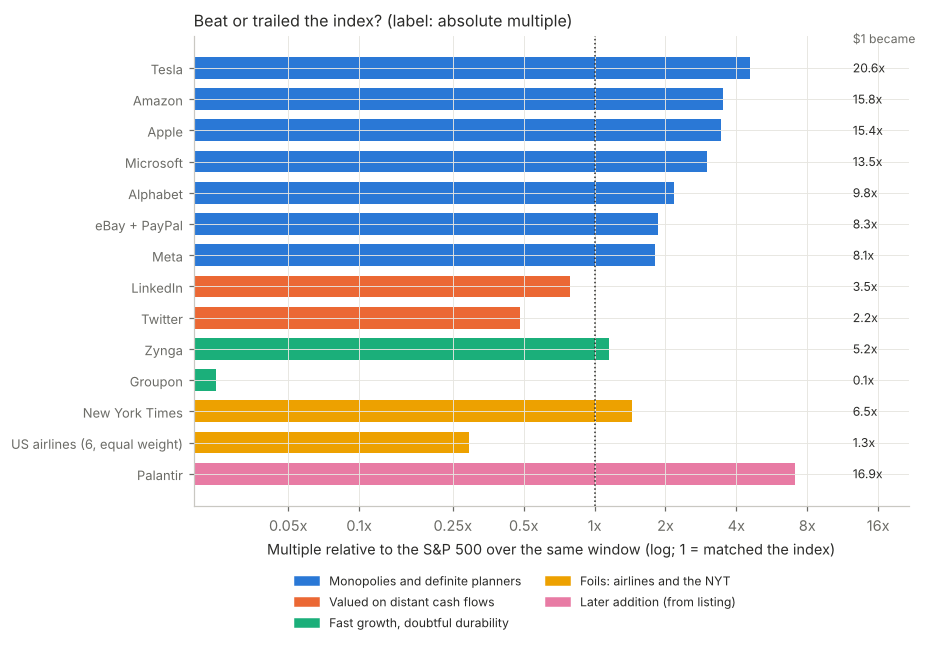

In [6]:
sc = score[score.group != "Benchmarks"].copy()
order = list(GROUPS) + ["Later addition (from listing)"]
sc["g"] = sc.group.map({g: i for i, g in enumerate(order)})
sc = sc.sort_values(["g", "vs_spy"], ascending=[False, True])
fig, ax = plt.subplots(figsize=(8.5, 6))
cols = [tc.C[int(g)] for g in sc.g]
ax.barh(range(len(sc)), sc.vs_spy, color=cols, height=0.7)
ax.axvline(1, color=tc.INK, ls=":", lw=1)
ax.set_xscale("log")
ticks = [0.05, 0.1, 0.25, 0.5, 1, 2, 4, 8, 16]
ax.set_xticks(ticks); ax.set_xticklabels([f"{v:g}x" for v in ticks]); ax.minorticks_off()
ax.set_yticks(range(len(sc))); ax.set_yticklabels(sc.name, fontsize=8.5)
xmax = max(8, sc.vs_spy.max() * 1.6); ax.set_xlim(min(0.05, sc.vs_spy.min() * 0.8), xmax * 1.9)
for i, (v, m) in enumerate(zip(sc.vs_spy, sc.multiple)):
    ax.text(xmax * 1.1, i, f"{m:.1f}x", va="center", ha="left", fontsize=8, color=tc.INK)
ax.text(xmax * 1.1, len(sc) - 0.3, "$1 became", va="bottom", ha="left", fontsize=8, color=tc.MUTED)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=tc.C[i], label=g) for i, g in enumerate(order) if g in set(sc.group)],
          loc="upper center", bbox_to_anchor=(0.45, -0.12), ncol=2, fontsize=8)
ax.set_xlabel("Multiple relative to the S&P 500 over the same window (log; 1 = matched the index)")
ax.set_title("Beat or trailed the index? (label: absolute multiple)", loc="left")
fig.tight_layout(); tc.save_fig(fig, "h4_fig2_vs_spy")

### Figure H4-3 · Two of the book's direct comparisons

* Thiel's foil pair from chapter 5: Twitter against the New York Times.
* His monopoly-versus-competition pair from chapter 3: Google against the airlines.

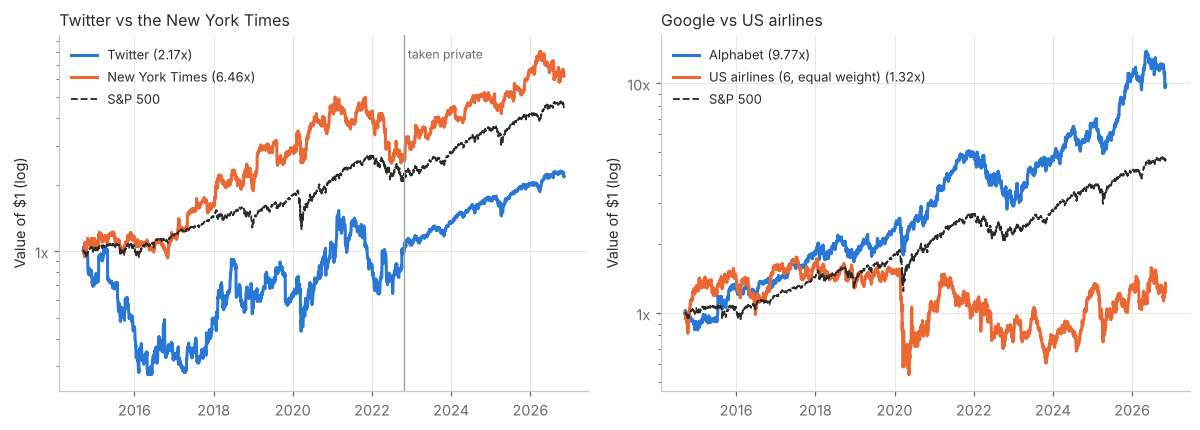

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pair in zip(axes, [("TWTR", "NYT"), ("GOOGL", "AIRLINES")]):
    for i, t in enumerate(pair):
        if t in W:
            w = W[t].dropna(); ax.plot(w.index, w.values, color=tc.C[i], lw=2, label=f"{NAMES[t]} ({w.iloc[-1]:.2f}x)")
    ax.plot(spy_tr.index, spy_tr.values, color=tc.INK, lw=1.2, ls="--", label="S&P 500")
    if pair[0] in DEALS: ax.axvline(DEALS[pair[0]][0], color=tc.GREY, lw=0.8); ax.text(DEALS[pair[0]][0], ax.get_ylim()[1], " taken private", fontsize=8, va="top", color=tc.MUTED)
    ax.set_yscale("log"); ax.legend(loc="upper left", fontsize=8.5); ax.set_ylabel("Value of $1 (log)")
    from matplotlib.ticker import FuncFormatter, NullFormatter
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}x")); ax.yaxis.set_minor_formatter(NullFormatter())
axes[0].set_title("Twitter vs the New York Times", loc="left"); axes[1].set_title("Google vs US airlines", loc="left")
fig.tight_layout(); tc.save_fig(fig, "h4_fig3_pairs")

## Verdict inputs and check cell — send me this output

In [8]:
def _r(x):
    try: return round(float(x), 3)
    except Exception: return str(x)
summary = {
    "window": [str(START.date()), str(END.date())],
    "missing": missing,
    "scorecard": [{k: _r(v) if k in ("multiple", "cagr_pct", "vs_spy", "max_drawdown_pct", "spy_multiple") else str(v)
                   for k, v in r.items()} for r in score.to_dict("records")],
    "groups": [{k: _r(v) if k in ("multiple", "cagr_pct", "vs_spy", "max_drawdown_pct", "spy_multiple") else str(v)
                for k, v in r.items()} for r in gs.to_dict("records")],
    "deals_cash_alternative": [{"ticker": r["ticker"], "multiple": _r(r["multiple"]), "vs_spy": _r(r["vs_spy"])} for r in alt.to_dict("records")],
}
(tc.OUT / "h4_summary.json").write_text(json.dumps(summary, indent=1, default=str))
print(json.dumps(summary, indent=1, default=str))

{
 "window": [
  "2014-09-16",
  "2026-11-06"
 ],
 "missing": [],
 "scorecard": [
  {
   "name": "Alphabet",
   "ticker": "GOOGL",
   "start": "2014-09-16",
   "end": "2026-11-06",
   "multiple": 9.766,
   "cagr_pct": 20.65,
   "spy_multiple": 4.497,
   "vs_spy": 2.172,
   "max_drawdown_pct": -44.32,
   "note": "",
   "group": "Monopolies and definite planners"
  },
  {
   "name": "Meta",
   "ticker": "META",
   "start": "2014-09-16",
   "end": "2026-11-06",
   "multiple": 8.097,
   "cagr_pct": 18.801,
   "spy_multiple": 4.497,
   "vs_spy": 1.801,
   "max_drawdown_pct": -76.736,
   "note": "",
   "group": "Monopolies and definite planners"
  },
  {
   "name": "Apple",
   "ticker": "AAPL",
   "start": "2014-09-16",
   "end": "2026-11-06",
   "multiple": 15.42,
   "cagr_pct": 25.276,
   "spy_multiple": 4.497,
   "vs_spy": 3.429,
   "max_drawdown_pct": -38.516,
   "note": "",
   "group": "Monopolies and definite planners"
  },
  {
   "name": "Amazon",
   "ticker": "AMZN",
   "start": "201